In [1]:

import pandas as pd
data=pd.read_csv(r'D:\UserBehavior.csv',header=None,names=['user_id','product_id','product_category_id','behavior','behavior_time'])
print("数据导入成功！")



数据导入成功！


In [2]:

print("商品个数：",data['product_id'].nunique())
print("商品种类数：",data['product_category_id'].nunique())
print("用户数：",data['user_id'].nunique())
#购买的用户信息
df1=data[data['behavior']=='buy'].copy()
#总购买人次
c=df1['user_id'].count()

df1=data[data['behavior']=='buy'].copy()
#各商品购买人次
df1['cnt']=df1.groupby('product_id')['user_id'].transform('count')
a=df1[['product_id','cnt']]
print("各商品购买人次：\n",a)

#各商品种类购买人次
b=df1.groupby('product_category_id')['user_id'].count()
print("各商品种类购买人次：\n",b)
print(data.isnull().sum())


商品个数： 4162024
商品种类数： 9439
用户数： 987994
各商品购买人次：
            product_id  cnt
71            1603476   38
73            2971043    1
100            598929    5
119           1046201    5
125           1606258    5
...               ...  ...
100150386     1309907    1
100150688      120487  205
100150689     4324714    3
100150694     3046611    3
100150785      444518   45

[2015839 rows x 2 columns]
各商品种类购买人次：
 product_category_id
2171       103
2410        14
2424         4
2818        12
3579         8
          ... 
5156420     24
5157813      5
5158474     78
5160054      8
5161669    142
Name: user_id, Length: 7097, dtype: int64
user_id                0
product_id             0
product_category_id    0
behavior               0
behavior_time          0
dtype: int64


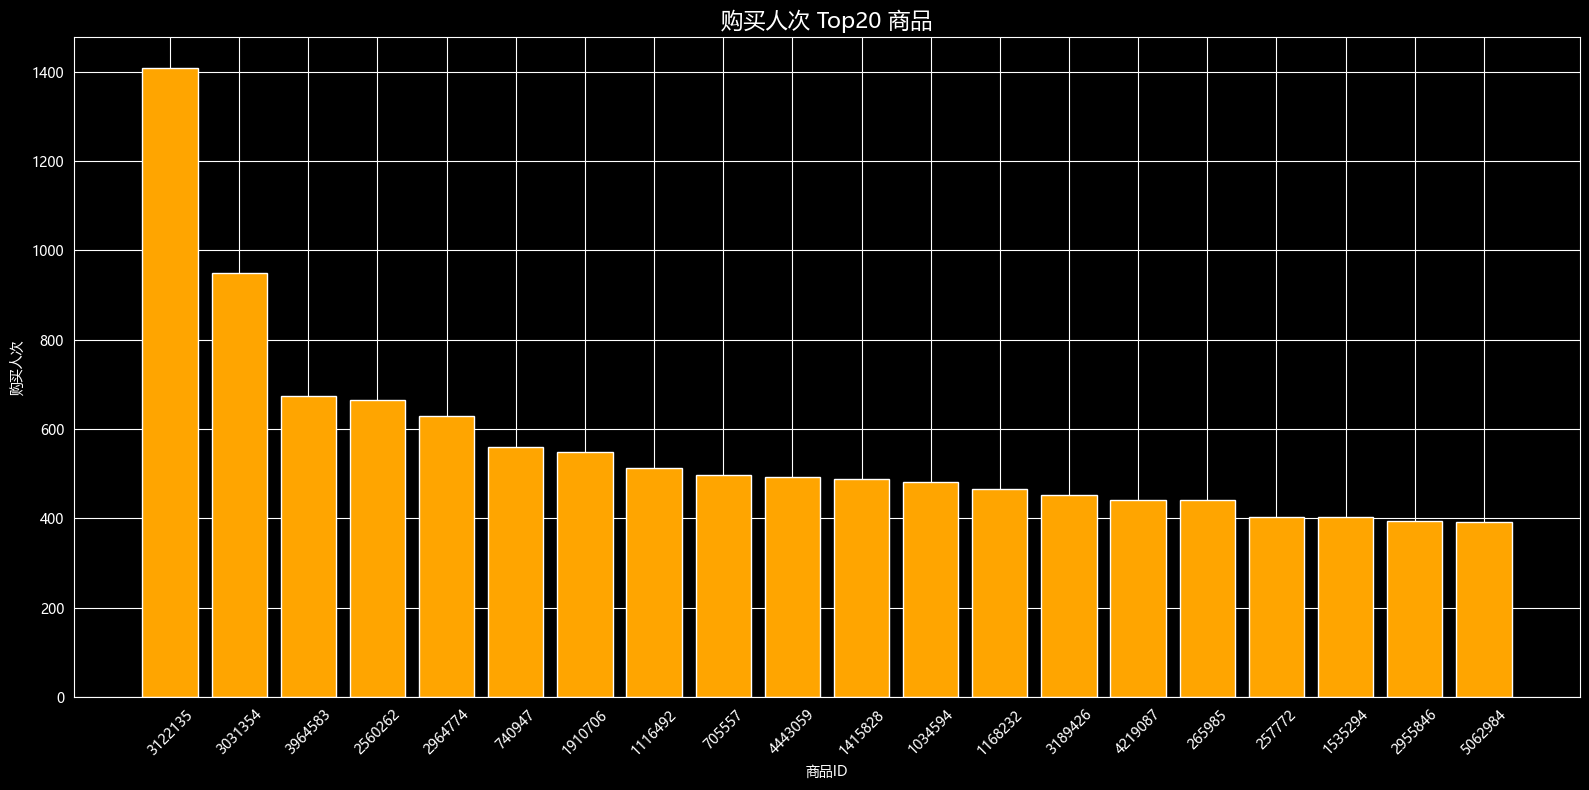

In [3]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']   # 列表形式，写全名
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False
top = (df1.groupby('product_id')['user_id'].count()
          .reset_index(name='buyer_num')
          .nlargest(20, 'buyer_num'))

plt.figure(figsize=(16, 8))
plt.bar(top['product_id'].astype(str), top['buyer_num'], color='orange')
plt.title('购买人次 Top20 商品', fontsize=16)
plt.xlabel('商品ID')
plt.ylabel('购买人次')
plt.xticks(rotation=45)      # 标签斜着放，防止重叠
plt.tight_layout()           # 自动调整边距，防标签被裁掉
plt.show()


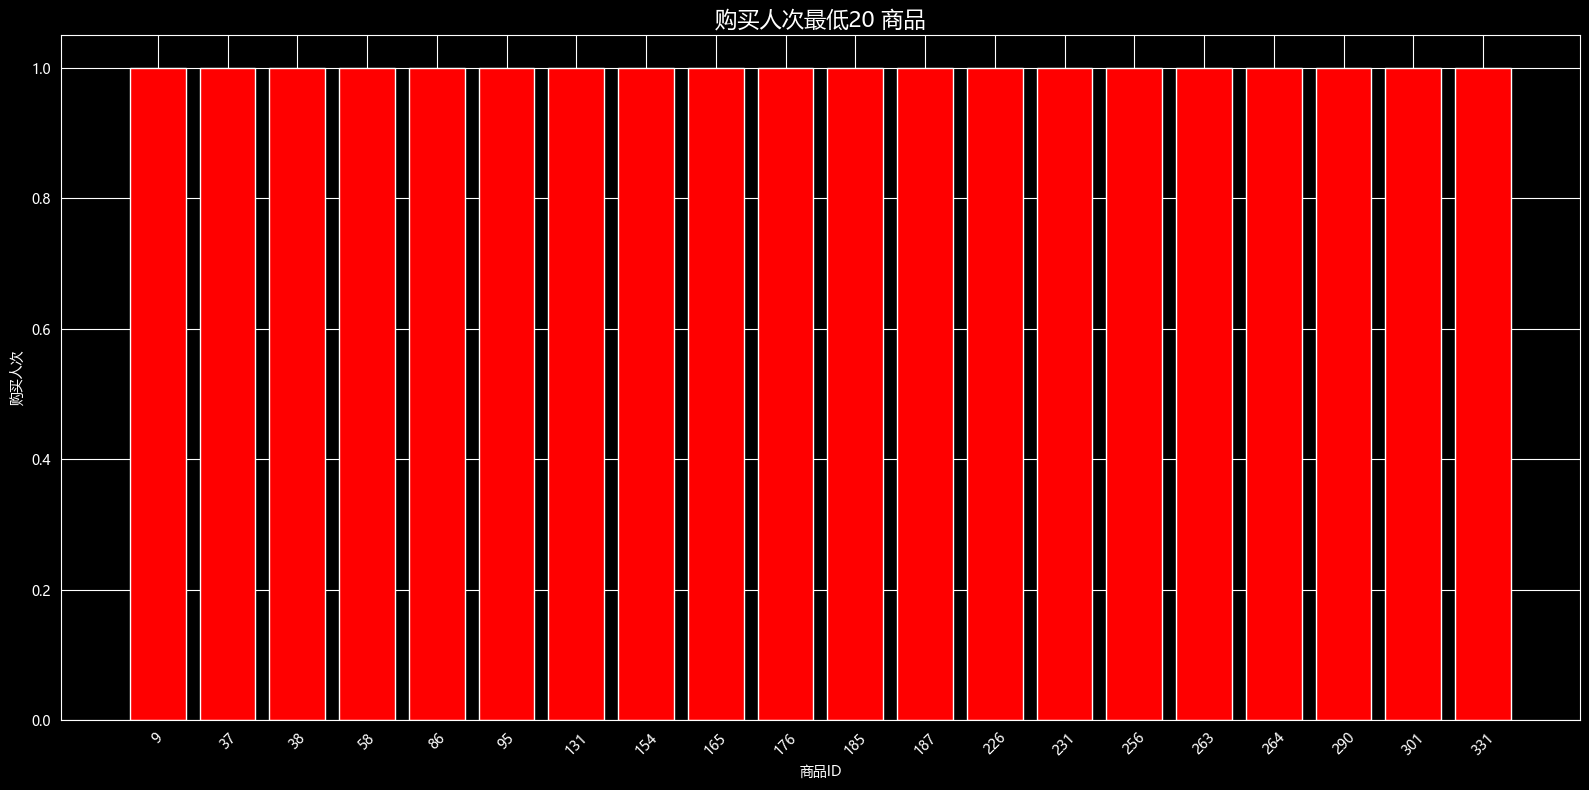

In [4]:
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']   # 列表形式，写全名
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.unicode_minus'] = False
last = (df1.groupby('product_id')['user_id'].count()
      .reset_index(name='buyer_num')
      .nsmallest(20, 'buyer_num'))
plt.figure(figsize=(16, 8))
plt.bar(last['product_id'].astype(str), last['buyer_num'], color='red')
plt.title('购买人次最低20 商品', fontsize=16)
plt.xlabel('商品ID')
plt.ylabel('购买人次')
plt.xticks(rotation=45)      # 标签斜着放，防止重叠
plt.tight_layout()           # 自动调整边距，防标签被裁掉
plt.show()

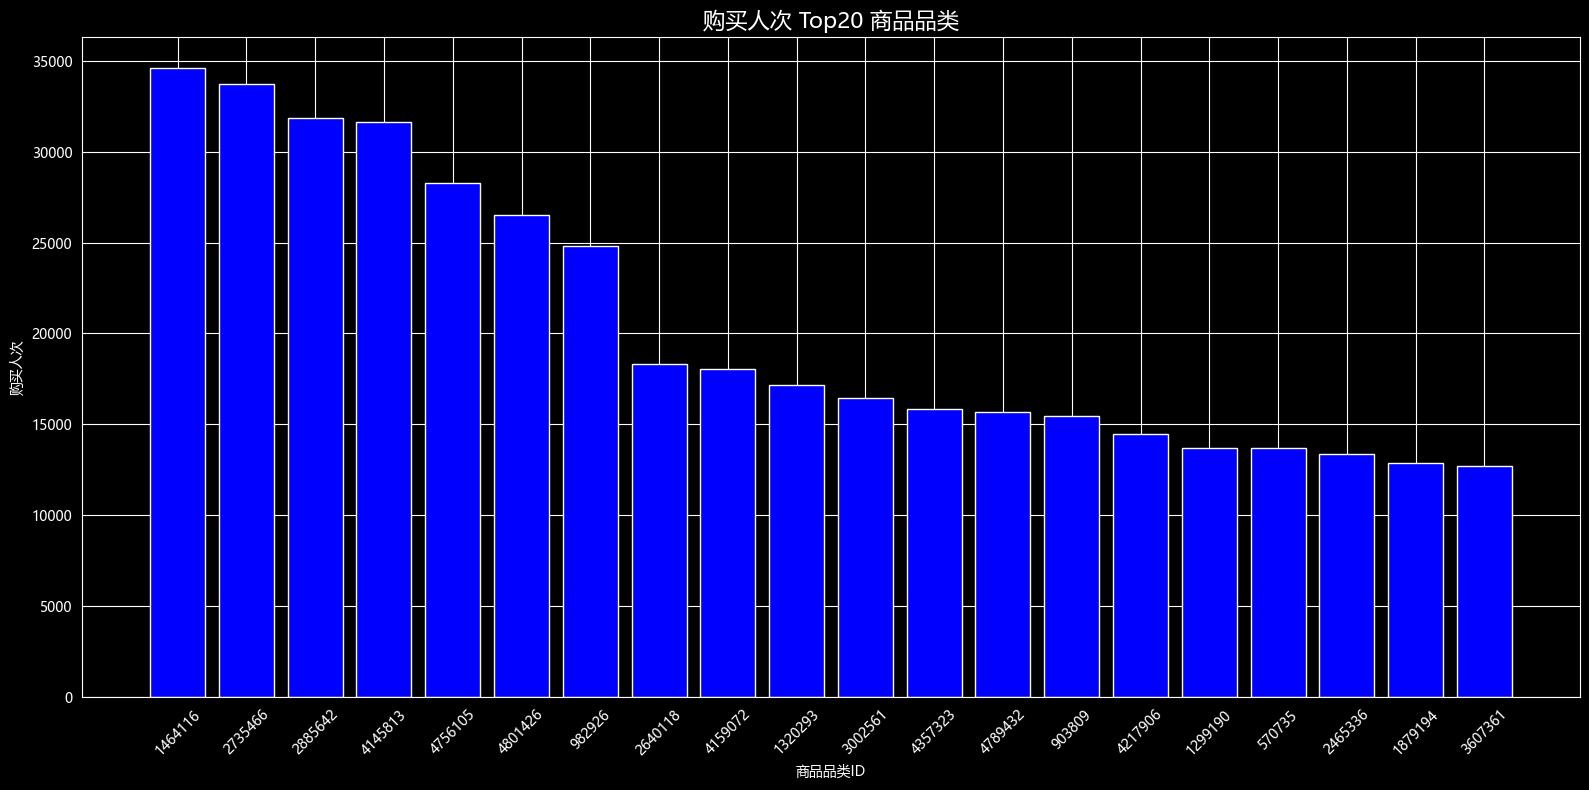

In [5]:
#商品品类卖得最多的20个品类
top_cat =(df1.groupby('product_category_id')['user_id'].count()
          .reset_index(name='buyer_num')
          .nlargest(20,'buyer_num'))
plt.figure(figsize=(16, 8))
plt.bar(top_cat['product_category_id'].astype(str), top_cat['buyer_num'], color='blue')
plt.title('购买人次 Top20 商品品类', fontsize=16)
plt.xlabel('商品品类ID')
plt.ylabel('购买人次')
plt.xticks(rotation=45)      # 标签斜着放，防止重叠
plt.tight_layout()           # 自动调整边距，防标签被裁掉
plt.show()

发现至少有20个商品的购买人次只有一个，购买人次最多的商品大约为1400人次，中间的巨大差异值得探究。但由于数据内容约束，该数据集不能进行分析，需要其他数据支撑。

In [10]:
#开始算购买转换率
#购买转换率定义：某商品被加入购物车后进行购买的人次/该商品被加入购物车的人次
#购物车-购物转化率
user_beh=data.groupby('user_id')['behavior'].agg(set)
only_cart=data[data['behavior']=='cart'].groupby(['user_id','product_id'])
print(only_cart)
only_cart_buy=user_beh[user_beh.apply(lambda x: x=={'pv','cart','buy'})].index
first_pv=(data[data['behavior']=='pv'].groupby(['user_id','product_id'])['behavior_time'].min()
          .rename('first_pv_time')
          )
first_cart=(data[data['behavior']=='cart'].groupby(['user_id','product_id'])['behavior_time'].min().rename('first_cart_time')
          )

buy_time=(
    data[data['behavior']=='buy'].groupby(['user_id','product_id'])['behavior_time'].min()
    .rename('buy_time')
)
g=pd.concat([first_pv,first_cart,buy_time],axis=1).dropna()
g['converted']=((g['first_cart_time']<=g['buy_time']) & (g['first_pv_time']<=g['first_cart_time']))
p1=round(g[g['converted']==True].shape[0]/only_cart.ngroups,4)
print('转化率为:',p1) #0.0129


转化率为: 0.0129


In [11]:
#收藏-购物转化率
only_fav=data[data['behavior']=='fav'].groupby(['user_id','product_id'])
only_fav_buy=user_beh[user_beh.apply(lambda x: x=={'pv','fav','buy'})].index
first_pv=(data[data['behavior']=='pv'].groupby(['user_id','product_id'])['behavior_time'].min()
          .rename('first_pv_time')
          )
first_fav=(data[data['behavior']=='fav'].groupby(['user_id','product_id'])['behavior_time'].min().rename('first_fav_time')
          )

buy_time=(
    data[data['behavior']=='buy'].groupby(['user_id','product_id'])['behavior_time'].min()
    .rename('buy_time')
)
n=pd.concat([first_pv,first_fav,buy_time],axis=1).dropna()
n['converted']=((n['first_fav_time']<=n['buy_time']) & (n['first_pv_time']<=n['first_fav_time']))
p2=round(n[n['converted']==True].shape[0]/only_fav.ngroups,4)
print('转化率为:',p2) #0.0094



转化率为: 0.0094


In [12]:
#点击-购物转化率
only_pv_buy=user_beh[user_beh.apply(lambda x: x=={'pv','buy'})].index
only_pv=data[data['behavior']=='pv'].groupby(['user_id','product_id'])
first_pv=(data[data['behavior']=='pv'].groupby(['user_id','product_id'])['behavior_time'].min()
          .rename('first_pv_time')
          )
buy_time=(
    data[data['behavior']=='buy'].groupby(['user_id','product_id'])['behavior_time'].min()
    .rename('buy_time')
)
m=pd.concat([first_pv,buy_time],axis=1).dropna()
m['converted']=(m['first_pv_time']<=m['buy_time'])
p3=round(m[m['converted']==True].shape[0]/only_pv.ngroups,4)
print('转化率为:',p3)#0.014

转化率为: 0.014


In [ ]:
#三种行为的人次占比-条形图
things=['购物车-购买','收藏-购买','点击-购买']
datas=[g[g['converted']==True].shape[0],n[n['converted']==True].shape[0],m[m['converted']==True].shape[0]]
plt.figure(figsize=(16, 8))
plt.barh(things,datas,align='center')
plt.title("三种路线的人数",fontsize=16)
plt.xlabel('人数')
plt.ylabel('行为路径')
plt.tight_layout()           # 自动调整边距，防标签被裁掉
plt.show()

In [14]:
#开始统计探究啦
#点击与购物车
import statsmodels.stats.proportion as ssp
dataz1=pd.DataFrame({'converted':[m[m['converted']==True].shape[0],g[g['converted']==True].shape[0]],'total':[only_pv.ngroups,only_cart.ngroups]})
z1_score,p1_value=ssp.proportions_ztest(count=dataz1.converted,nobs=dataz1.total,alternative='two-sided')
print("点击-购物车的Z值为：",z1_score)
print("点击-购物车的P值为：",p1_value)
print("有证据说明加入购物车行为能够提升转化率" if p1_value<0.05 else"不能说明加入购物车行为能够提升转化率")

#收藏与购物车
dataz2=pd.DataFrame({'converted':[n[n['converted']==True].shape[0],g[g['converted']==True].shape[0]],'total':[only_fav.ngroups,only_cart.ngroups]})
z2_score,p2_value=ssp.proportions_ztest(count=dataz2.converted,nobs=dataz2.total,alternative='two-sided')
print("收藏-购物车的Z值为：",z2_score)
print("收藏-购物车的P值为：",p2_value)
print("有证据说明加入购物车行为能够提升转化率" if p2_value<0.05 else"不能说明加入购物车行为能够提升转化率")



点击-购物车的Z值为： 19.80498513238683
点击-购物车的P值为： 2.6964243569409055e-87
有证据说明加入购物车行为能够提升转化率
收藏-购物车的Z值为： -45.604961023628455
收藏-购物车的P值为： 0.0
有证据说明加入购物车行为能够提升转化率
